In [1]:
import numpy as np
import spectres
import pickle
import matplotlib.pyplot as plt 
from POSEIDON.core import (create_star,create_planet,define_model,make_atmosphere,compute_spectrum,wl_grid_constant_R,read_opacities)
from POSEIDON.constants import R_J,R_Sun,M_J

In [2]:
N_layers = 100
freckll_p = np.logspace(2,-5,N_layers)

#===POSEIDON's grid===
P_min = 1.0e-7
P_max = 10
P=  np.logspace(np.log10(P_max),np.log10(P_min),N_layers)

print("FRECKLL P range: {:.1e} to {:.1e} bar".format(freckll_p[0], freckll_p[-1]))
print("POSEIDON P range: {:.1e} to {:.1e} bar".format(P[0], P[-1]))

FRECKLL P range: 1.0e+02 to 1.0e-05 bar
POSEIDON P range: 1.0e+01 to 1.0e-07 bar


In [3]:
h2o = np.load("FRECKLL_vmr/h2o_profile.npy")
print("H2O done")
ch4 = np.load("FRECKLL_vmr/ch4_profile.npy")
print("CH4 done")
co2 = np.load("FRECKLL_vmr/co2_profile.npy")
print("CO2 done")
nh3 = np.load("FRECKLL_vmr/nh3_profile.npy")
print("NH3 done")
co  = np.load("FRECKLL_vmr/co_profile.npy")
print("CO done")
print("\nLoaded VMR shapes:", h2o.shape, ch4.shape, co.shape, co2.shape, nh3.shape)

H2O done
CH4 done
CO2 done
NH3 done
CO done

Loaded VMR shapes: (100,) (100,) (100,) (100,) (100,)


In [4]:
log_freckll_P = np.log10(freckll_p)
log_poseidon_P = np.log10(P)

In [5]:
def interp_vmr(vmr_profile):
    return np.interp(log_poseidon_P,log_freckll_P[::-1],vmr_profile[::-1])

h2o_interp = interp_vmr(h2o)
ch4_interp = interp_vmr(ch4)
co_interp  = interp_vmr(co)
co2_interp = interp_vmr(co2)
nh3_interp = interp_vmr(nh3)

print("Interpolation done.")
print("H2O at deepest layer: {:.3e}".format(h2o_interp[0]))
print("H2O at top layer:     {:.3e}".format(h2o_interp[-1]))


Interpolation done.
H2O at deepest layer: 6.234e-04
H2O at top layer:     4.967e-04


In [6]:
T_input = np.full(N_layers, 1500.0) #isothermal
he_profile = np.full(N_layers, 0.17)
h2_profile = np.full(N_layers, 0.83)
X_input = np.array([h2_profile,he_profile,h2o_interp,ch4_interp,co_interp,co2_interp,nh3_interp])
print("T_input shape:", T_input.shape)
print("X_input shape:", X_input.shape) 

T_input shape: (100,)
X_input shape: (7, 100)


In [7]:
#===Planet parameters===
Rp_Rj    = 1.37   # planet radius in Jupiter radii
Mp_Mj    = 0.87   # planet mass in Jupiter masses
Rstar_Rs = 1.0    # star radius in Solar radii
T_eq     = 1500.0

R_p   = Rp_Rj * R_J      # metres
M_p   = Mp_Mj * M_J      # kg
R_s   = Rstar_Rs * R_Sun  # metres

star   = create_star(R_s, 5778.0, 4.44, 0.0)
planet = create_planet('freckll_disequil', R_p, mass=M_p, T_eq=T_eq)
print("Star and planet objects created.")

Star and planet objects created.


In [8]:
#===Wavelength grid===

wl_min = 0.4 
wl_max = 10
R_highres = 15000
wl_highres = wl_grid_constant_R(wl_min, wl_max, R_highres)
print("High-res wavelength grid:", wl_highres.shape)

wl_binned = np.load("free_chem_data/wl_binned.npy")
print("Binned wavelength grid:", wl_binned.shape)

OPAC_FILE = "opacities_created/opac_eq_chemistry.pickle"
with open(OPAC_FILE, 'rb') as f:
    opac = pickle.load(f)
print("Opacities loaded from pickle.")


High-res wavelength grid: (48283,)
Binned wavelength grid: (52,)
Opacities loaded from pickle.


In [9]:
bulk_species  = ['H2', 'He']
param_species = ['H2O', 'CH4', 'CO', 'CO2', 'NH3']

model = define_model('freckll_disequil_model',bulk_species,param_species,PT_profile = 'file_read',X_profile  = 'file_read')
print("Model defined.")
print("Chemical species in model:", model['chemical_species'])

Model defined.
Chemical species in model: ['H2' 'He' 'H2O' 'CH4' 'CO' 'CO2' 'NH3']


In [10]:
P_ref = 10.0
R_p_ref = R_p
atmosphere = make_atmosphere(planet,model,P,P_ref,R_p_ref,T_input=T_input,X_input=X_input)

print("Atmosphere created successfully.")

Atmosphere created successfully.


In [11]:
spectrum_highres = compute_spectrum(planet,star,model,atmosphere,opac,wl_highres,spectrum_type='transmission')
spectrum_binned = spectres.spectres(wl_binned, wl_highres, spectrum_highres, verbose=False)
print("Spectrum computed.")
print("High-res shape:", spectrum_highres.shape)
print("Binned shape:  ", spectrum_binned.shape)

# Sanity checks
print("\nAny NaN?", np.any(np.isnan(spectrum_binned)))
print("Any Inf?", np.any(np.isinf(spectrum_binned)))
print("Min value:", spectrum_binned.min())
print("Max value:", spectrum_binned.max())

Spectrum computed.
High-res shape: (48283,)
Binned shape:   (52,)

Any NaN? False
Any Inf? False
Min value: 0.020631068429630656
Max value: 0.022003011187541322


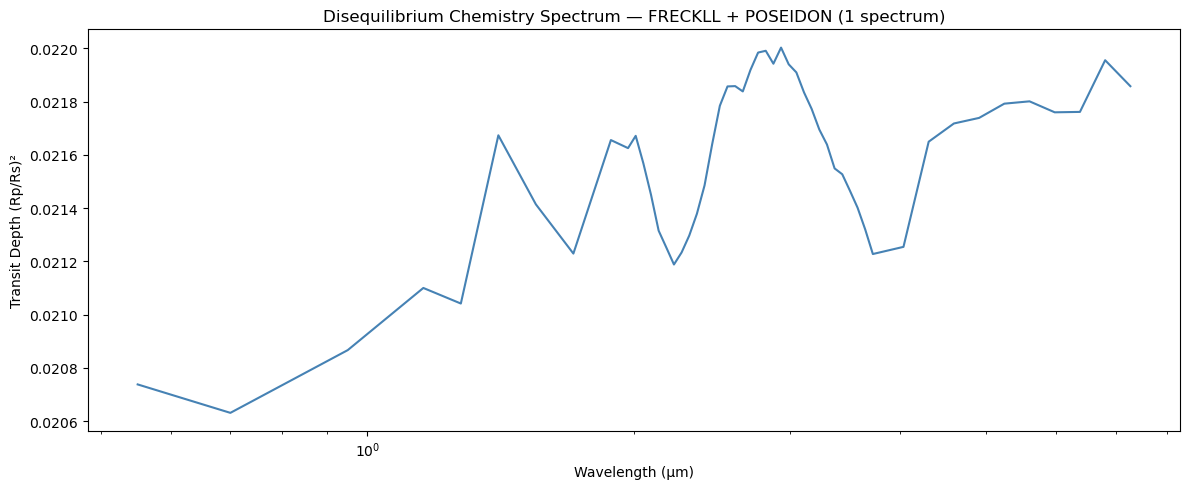

In [12]:
# Plot
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(wl_binned, spectrum_binned, color='steelblue', linewidth=1.5)
ax.set_xlabel('Wavelength (μm)')
ax.set_ylabel('Transit Depth (Rp/Rs)²')
ax.set_title('Disequilibrium Chemistry Spectrum — FRECKLL + POSEIDON (1 spectrum)')
ax.set_xscale('log')
plt.tight_layout()
plt.show()